
# Exploratory Data Analysis (EDA)

## Project: E-commerce Data Analysis

### Objective
To explore the cleaned e-commerce dataset, identify sales trends,
understand customer purchasing behaviour, evaluate product and
category performance, and discover actionable business insights.

### Analysis Areas
1. Overall Sales Performance
2. Monthly Sales Trends
3. Product Performance
4. Category-wise Sales
5. Customer Analysis
6. Payment Method Analysis
7. Order Status Analysis


In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load cleaned dataset
df = pd.read_csv("../dataset/cleaned_ecommerce_sales.csv")

# Display confirmation
print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Cleaned dataset loaded successfully!
Dataset shape: (102, 15)


,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Original_Total,Gross_Amount,Total_Difference,Total_Check
0,100,Customer_100,ORD-41285,2024-11-22,Blender,Home,3.0,38.00,Cash on Delivery,Shipped,114.00,114.00,114.00,0.0,Matches Gross Amount
1,101,Customer_101,ORD-35783,2025-07-05,Smartphone,Electronics,2.0,NaN,PayPal,Processing,NaN,NaN,NaN,NaN,Insufficient Gross Data
2,102,Customer_102,ORD-84355,2024-12-23,Tennis Racket,Sports,1.0,389.05,PayPal,Delivered,389.05,389.05,389.05,0.0,Matches Gross Amount
3,103,Customer_103,ORD-57811,2025-03-19,Science,Books,5.0,233.92,PayPal,Processing,1169.60,1169.60,1169.60,0.0,Matches Gross Amount
4,104,Customer_104,ORD-93614,2025-10-20,Biography,Books,1.0,552.51,Cash on Delivery,Processing,552.51,552.51,552.51,0.0,Matches Gross Amount


In [2]:

# Check the first five records without truncating columns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

print("First 5 records:")
display(df.head())

# Check data types
print("\nColumn data types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check payment methods
print("\nPayment method values:")
print(df["Payment_Method"].value_counts(dropna=False))

# Check order statuses
print("\nOrder status values:")
print(df["Status"].value_counts(dropna=False))


First 5 records:


,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Original_Total,Gross_Amount,Total_Difference,Total_Check
0,100,Customer_100,ORD-41285,2024-11-22,Blender,Home,3.0,38.00,Cash on Delivery,Shipped,114.00,114.00,114.00,0.0,Matches Gross Amount
1,101,Customer_101,ORD-35783,2025-07-05,Smartphone,Electronics,2.0,NaN,PayPal,Processing,NaN,NaN,NaN,NaN,Insufficient Gross Data
2,102,Customer_102,ORD-84355,2024-12-23,Tennis Racket,Sports,1.0,389.05,PayPal,Delivered,389.05,389.05,389.05,0.0,Matches Gross Amount
3,103,Customer_103,ORD-57811,2025-03-19,Science,Books,5.0,233.92,PayPal,Processing,1169.60,1169.60,1169.60,0.0,Matches Gross Amount
4,104,Customer_104,ORD-93614,2025-10-20,Biography,Books,1.0,552.51,Cash on Delivery,Processing,552.51,552.51,552.51,0.0,Matches Gross Amount



Column data types:
ID                    int64
Customer_Name           str
Order_ID                str
Order_Date              str
Product                 str
Category                str
Quantity            float64
Price               float64
Payment_Method          str
Status                  str
Total               float64
Original_Total      float64
Gross_Amount        float64
Total_Difference    float64
Total_Check             str
dtype: object

Missing values:
ID                   0
Customer_Name        0
Order_ID             0
Order_Date           1
Product              0
Category             2
Quantity             8
Price                8
Payment_Method       0
Status               0
Total               14
Original_Total      14
Gross_Amount        15
Total_Difference    17
Total_Check          0
dtype: int64

Payment method values:
Payment_Method
Cash on Delivery    33
PayPal              24
Credit Card         23
Bank Transfer       22
Name: count, dtype: int64

Order status 


## 1. Overall Sales Performance

This analysis provides an overview of e-commerce business performance.

Key metrics include total recorded sales, transaction count, unique customers,
total units sold, and average recorded transaction value.

The analysis uses available recorded Total values. Missing totals are not
estimated or replaced, so the sales figure represents the available records.


In [3]:

# ==========================================
# 1. OVERALL SALES PERFORMANCE
# ==========================================

# Convert Order_Date into datetime format
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

# Calculate key business metrics
total_sales = df["Total"].sum()

total_transactions = len(df)

unique_customers = df["Customer_Name"].nunique()

unique_orders = df["Order_ID"].nunique()

total_units_sold = df["Quantity"].sum()

valid_sales_records = df["Total"].count()

average_transaction_value = (
    total_sales / valid_sales_records
    if valid_sales_records > 0 else 0
)

# Display results
print("OVERALL SALES PERFORMANCE")
print("=" * 40)

print(f"Total Recorded Sales:       {total_sales:,.2f}")
print(f"Total Transaction Records:  {total_transactions}")
print(f"Unique Customers:           {unique_customers}")
print(f"Unique Order IDs:            {unique_orders}")
print(f"Total Units Sold:            {total_units_sold:,.0f}")
print(f"Valid Sales Records:         {valid_sales_records}")
print(f"Average Recorded Value:      {average_transaction_value:,.2f}")
print(f"Missing Sales Records:       {df['Total'].isna().sum()}")


OVERALL SALES PERFORMANCE
Total Recorded Sales:       108,321.63
Total Transaction Records:  102
Unique Customers:           100
Unique Order IDs:            100
Total Units Sold:            288
Valid Sales Records:         88
Average Recorded Value:      1,230.93
Missing Sales Records:       14


## Create a sales summary visualization

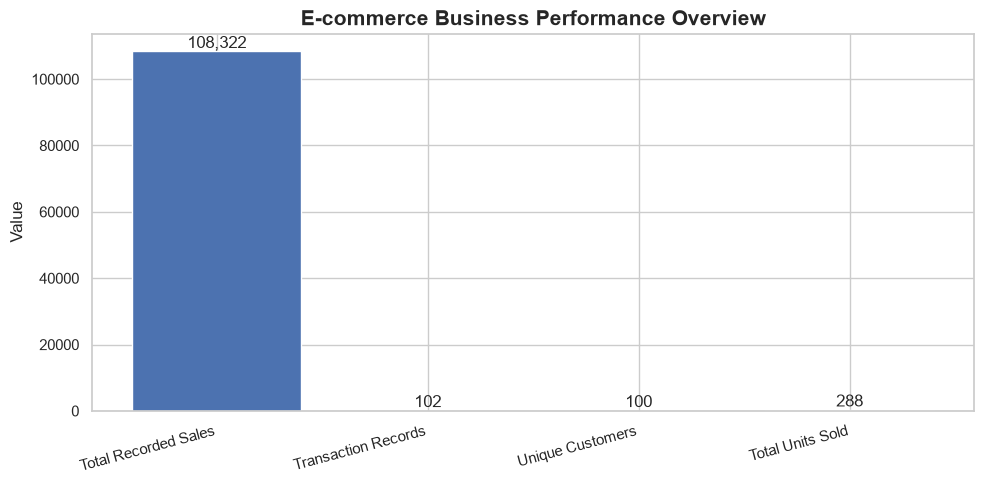

In [4]:

# ==========================================
# OVERALL SALES SUMMARY VISUALIZATION
# ==========================================

metrics = {
    "Total Recorded Sales": total_sales,
    "Transaction Records": total_transactions,
    "Unique Customers": unique_customers,
    "Total Units Sold": total_units_sold
}

plt.figure(figsize=(10, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.title("E-commerce Business Performance Overview",
          fontsize=15, fontweight="bold")

plt.ylabel("Value")
plt.xticks(rotation=15, ha="right")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### Total recorded sales

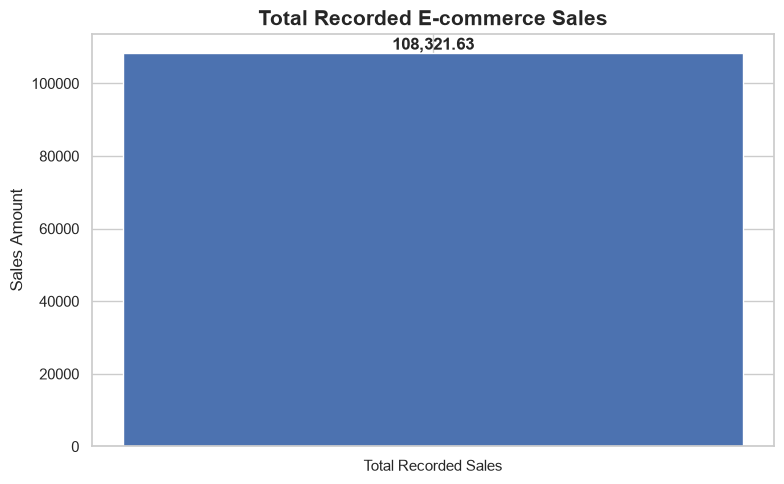

In [5]:

# ==========================================
# CHART 1: TOTAL RECORDED SALES
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Total Recorded Sales"],
    [total_sales],
    width=0.45
)

plt.title(
    "Total Recorded E-commerce Sales",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Sales Amount")

plt.text(
    0,
    total_sales,
    f"{total_sales:,.2f}",
    ha="center",
    va="bottom",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Transaction and customer overview

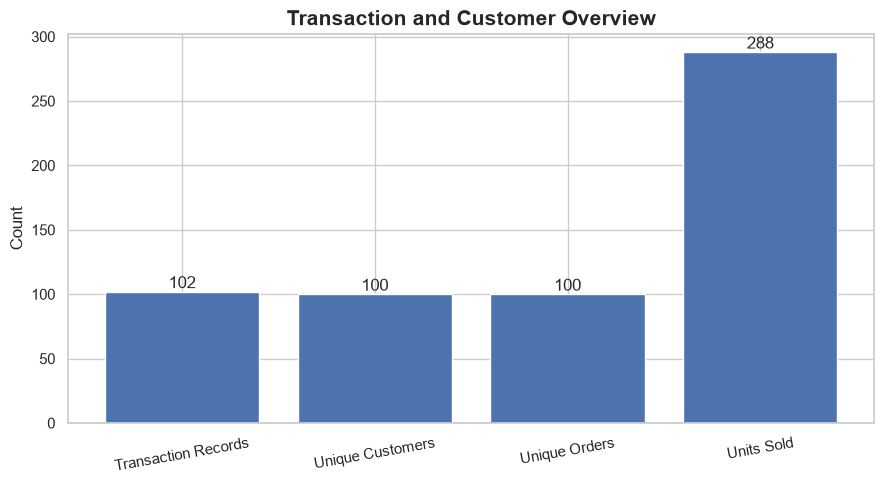

In [6]:

# ==========================================
# CHART 2: TRANSACTION AND CUSTOMER OVERVIEW
# ==========================================

count_metrics = {
    "Transaction Records": total_transactions,
    "Unique Customers": unique_customers,
    "Unique Orders": unique_orders,
    "Units Sold": total_units_sold
}

plt.figure(figsize=(9, 5))

bars = plt.bar(
    count_metrics.keys(),
    count_metrics.values()
)

plt.title(
    "Transaction and Customer Overview",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Count")
plt.xticks(rotation=10)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



### Key Findings – Overall Sales Performance

1. The dataset contains 102 transaction records from 100 unique customers.

2. Total recorded sales amount to 108,321.63 across 88 records with available sales values.

3. A total of 288 units were recorded as sold, excluding missing quantities.

4. The average recorded transaction value among records with available totals is 1,230.93.

5. Fourteen transaction records have missing sales values and require further investigation.

### Business Recommendation

The business should improve transaction data validation to reduce missing sales values and investigate repeated order IDs. This will improve the reliability of sales reporting and business decisions.


## EDA – Analysis 2: Monthly Sales Trends
Objective: Understand how recorded sales change over time and identify the strongest and weakest sales months.

We'll investigate:
1. Monthly recorded sales.
2. Highest and lowest sales months.
3. Monthly transaction volume.
4. Sales trend over the available period.


## 2. Monthly Sales Trends

### Objective

Analyze monthly e-commerce sales performance to identify sales
patterns, high-performing months, low-performing months, and
changes in business performance over time.

### Key Metrics
- Monthly Recorded Sales
- Monthly Transaction Count
- Highest Sales Month
- Lowest Sales Month


## Calculate monthly sales

In [7]:

# ==========================================
# 2. MONTHLY SALES ANALYSIS
# ==========================================

# Create a copy containing valid order dates
monthly_df = df.dropna(subset=["Order_Date"]).copy()

# Group data by month
monthly_sales = (
    monthly_df
    .groupby(monthly_df["Order_Date"].dt.to_period("M"))
    .agg(
        Monthly_Sales=("Total", "sum"),
        Transaction_Count=("Order_ID", "count"),
        Valid_Sales_Records=("Total", "count")
    )
    .reset_index()
)

# Convert period into readable month format
monthly_sales["Month"] = (
    monthly_sales["Order_Date"].dt.to_timestamp()
)

# Display monthly results
print("MONTHLY SALES SUMMARY")
print("=" * 50)

display(monthly_sales)


MONTHLY SALES SUMMARY


,Order_Date,Monthly_Sales,Transaction_Count,Valid_Sales_Records,Month
0,2023-01,1532.040,2,2,2023-01-01
1,2023-05,1721.980,1,1,2023-05-01
2,2024-11,11323.350,9,8,2024-11-01
3,2024-12,7027.810,7,6,2024-12-01
4,2025-01,11373.326,5,5,2025-01-01
5,2025-02,-830.708,14,12,2025-02-01
6,2025-03,5675.860,5,4,2025-03-01
7,2025-04,1200.280,2,2,2025-04-01
8,2025-05,10959.030,9,8,2025-05-01
9,2025-06,16376.430,9,7,2025-06-01


## Identify the highest and lowest sales months

In [8]:

# ==========================================
# HIGHEST AND LOWEST SALES MONTHS
# ==========================================

highest_month = monthly_sales.loc[
    monthly_sales["Monthly_Sales"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["Monthly_Sales"].idxmin()
]

print("HIGHEST SALES MONTH")
print("-" * 35)

print("Month:", highest_month["Month"].strftime("%B %Y"))
print(f"Recorded Sales: {highest_month['Monthly_Sales']:,.2f}")

print("\nLOWEST SALES MONTH")
print("-" * 35)

print("Month:", lowest_month["Month"].strftime("%B %Y"))
print(f"Recorded Sales: {lowest_month['Monthly_Sales']:,.2f}")


HIGHEST SALES MONTH
-----------------------------------
Month: June 2025
Recorded Sales: 16,376.43

LOWEST SALES MONTH
-----------------------------------
Month: February 2025
Recorded Sales: -830.71


## Create a monthly sales trend chart

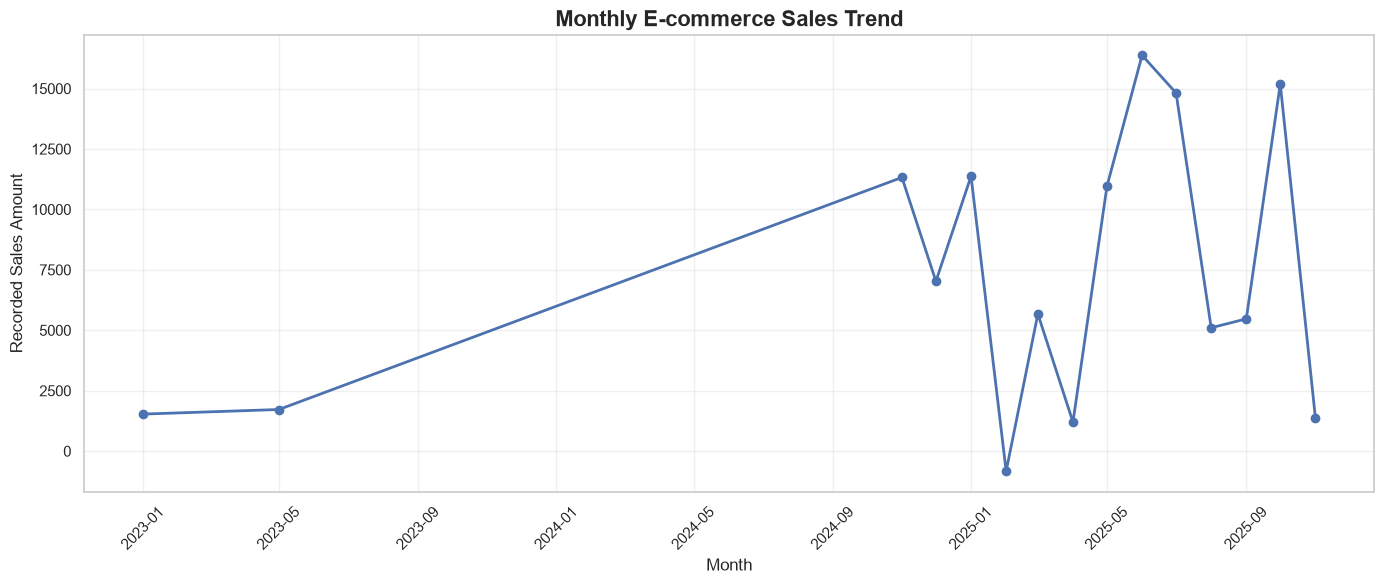

In [9]:

# ==========================================
# MONTHLY SALES TREND VISUALIZATION
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Monthly_Sales"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly E-commerce Sales Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Recorded Sales Amount")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Create a monthly transaction chart

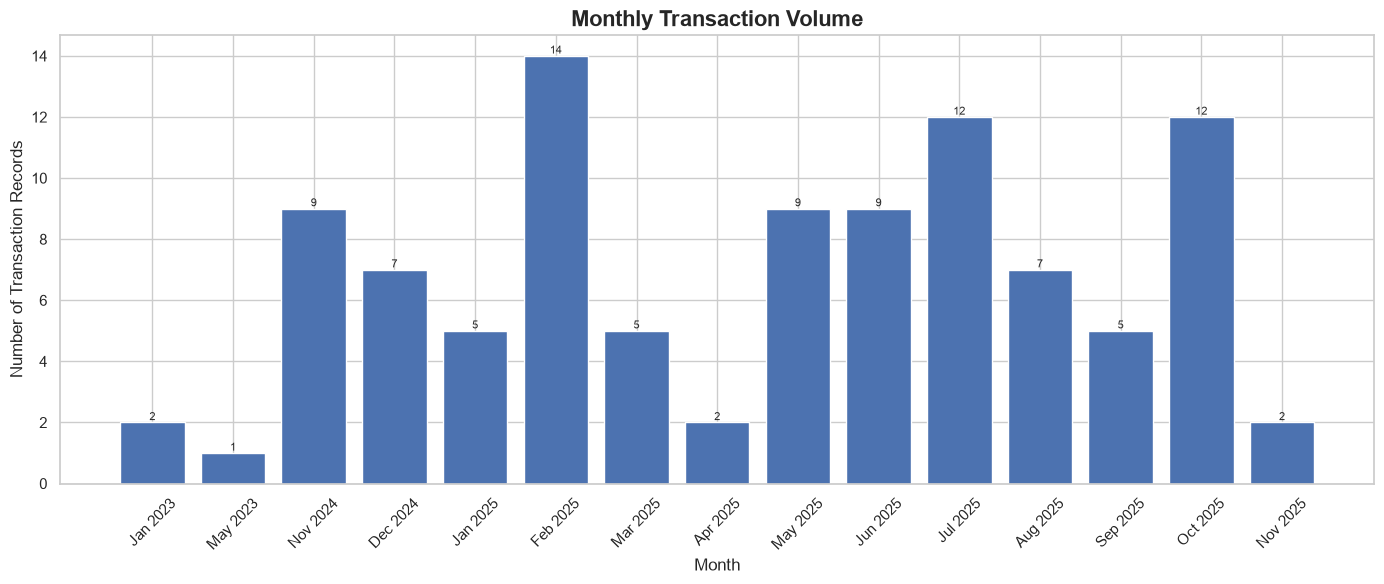

In [10]:

# ==========================================
# MONTHLY TRANSACTION COUNT
# ==========================================

plt.figure(figsize=(14, 6))

bars = plt.bar(
    monthly_sales["Month"].dt.strftime("%b %Y"),
    monthly_sales["Transaction_Count"]
)

plt.title(
    "Monthly Transaction Volume",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Number of Transaction Records")

plt.xticks(rotation=45)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()


## Investigate negative sales values

In [11]:
# ==========================================
# INVESTIGATION: NEGATIVE RECORDED SALES
# ==========================================

# Find records with negative Total values
negative_sales = df[df["Total"] < 0].copy()

print("NEGATIVE SALES RECORDS")
print("=" * 45)

print("Number of negative sales records:", len(negative_sales))

display(
    negative_sales[
        [
            "ID",
            "Order_ID",
            "Order_Date",
            "Product",
            "Category",
            "Quantity",
            "Price",
            "Total",
            "Status"
        ]
    ]
)

print("\nNegative sales by order status:")
display(negative_sales["Status"].value_counts())

NEGATIVE SALES RECORDS
Number of negative sales records: 3


,ID,Order_ID,Order_Date,Product,Category,Quantity,Price,Total,Status
17,117,ORD-72751,2025-02-12,Blender,Electronics,NaN,10000.00,-20000.00,Processing
34,134,ORD-16585,2025-10-04,T-Shirt,Clothing,NaN,591.53,-2957.65,Shipped
37,137,ORD-91254,2025-02-23,Vacuum,Home,3.0,NaN,-300.00,Delivered



Negative sales by order status:


Status
Processing    1
Shipped       1
Delivered     1
Name: count, dtype: int64

In [12]:
# ==========================================
# FEBRUARY 2025 SALES INVESTIGATION
# ==========================================

february_df = df[
    (df["Order_Date"].dt.year == 2025) &
    (df["Order_Date"].dt.month == 2)
].copy()

print("FEBRUARY 2025 TRANSACTIONS")
print("=" * 45)

display(
    february_df[
        [
            "ID",
            "Order_ID",
            "Product",
            "Quantity",
            "Price",
            "Total",
            "Status",
            "Total_Check"
        ]
    ]
)

print("\nFebruary recorded sales:", february_df["Total"].sum())
print("Negative Total records:", (february_df["Total"] < 0).sum())
print("Missing Total records:", february_df["Total"].isna().sum())

print("\nSales by order status:")
display(
    february_df.groupby("Status")["Total"]
    .agg(["count", "sum"])
)

FEBRUARY 2025 TRANSACTIONS


,ID,Order_ID,Product,Quantity,Price,Total,Status,Total_Check
6,106,ORD-25885,Blender,NaN,978.63,NaN,Processing,Insufficient Gross Data
17,117,ORD-72751,Blender,NaN,10000.00,-20000.000,Processing,Insufficient Gross Data
25,125,ORD-23202,Comics,4.0,765.69,3062.760,Shipped,Matches Gross Amount
35,135,ORD-33656,Smartwatch,4.0,446.19,1784.760,Cancelled,Matches Gross Amount
37,137,ORD-91254,Vacuum,3.0,NaN,-300.000,Delivered,Insufficient Gross Data
39,139,ORD-38418,Smartphone,2.0,681.38,1362.760,Cancelled,Matches Gross Amount
40,140,ORD-67096,Fiction,4.0,588.98,2355.920,Returned,Matches Gross Amount
41,141,ORD-45059,Fiction,3.0,546.04,1638.120,Returned,Matches Gross Amount
54,154,ORD-95990,Blender,5.0,789.64,3948.200,Cancelled,Matches Gross Amount
64,164,ORD-23010,Tennis Racket,NaN,587.64,NaN,Returned,Insufficient Gross Data



February recorded sales: -830.7080000000008
Negative Total records: 2
Missing Total records: 2

Sales by order status:


,count,sum
Status,,
Cancelled,3,7095.720
Delivered,1,-300.000
Processing,4,-19405.928
Returned,3,8716.740
Shipped,1,3062.760


## Improve the monthly sales chart

In [14]:
# ==========================================
# CLEAN MONTHLY SALES TIMELINE
# ==========================================

final_monthly_timeline = complete_monthly_sales[
    [
        "Monthly_Sales",
        "Transaction_Count",
        "Valid_Sales_Records"
    ]
].copy()

final_monthly_timeline.index = (
    final_monthly_timeline.index.strftime("%b %Y")
)

display(final_monthly_timeline)

,Monthly_Sales,Transaction_Count,Valid_Sales_Records
Month,,,
Jan 2023,1532.040,2.0,2.0
Feb 2023,0.000,0.0,0.0
Mar 2023,0.000,0.0,0.0
Apr 2023,0.000,0.0,0.0
May 2023,1721.980,1.0,1.0
Jun 2023,0.000,0.0,0.0
Jul 2023,0.000,0.0,0.0
Aug 2023,0.000,0.0,0.0
Sep 2023,0.000,0.0,0.0


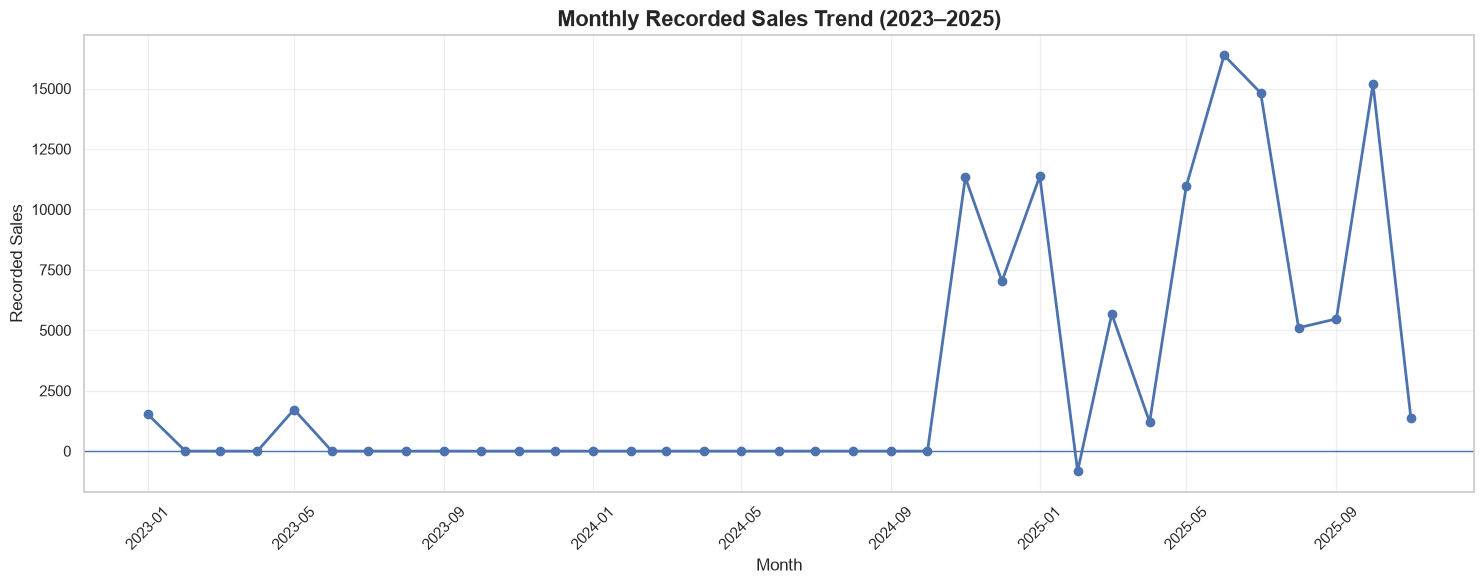

In [15]:
# ==========================================
# CONTINUOUS MONTHLY SALES TREND
# ==========================================

plt.figure(figsize=(15, 6))

plt.plot(
    complete_monthly_sales.index,
    complete_monthly_sales["Monthly_Sales"],
    marker="o",
    linewidth=2
)

plt.axhline(0, linewidth=1)

plt.title(
    "Monthly Recorded Sales Trend (2023–2025)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Recorded Sales")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Key Findings – Monthly Sales Trends

1. June 2025 recorded the highest monthly sales of 16,376.43.

2. February 2025 recorded the lowest monthly sales of -830.71, mainly due to two negative transaction totals.

3. February 2025 had the highest transaction volume, with 14 transaction records, but its recorded sales were negative.

4. October 2025 recorded 15,184.11 in sales, making it another strong-performing month.

5. The dataset has no transaction records for several months, particularly between May 2023 and November 2024. Therefore, a continuous growth trend cannot be established from the available data.

### Business Recommendations

- Investigate negative transaction totals and validate refund or adjustment records.
- Introduce checks to prevent missing or invalid quantity and price values.
- Monitor monthly sales and transaction volume together rather than relying on only one metric.
- Maintain more consistent transaction records to improve sales forecasting and reporting.



## 3. Product Performance Analysis

### Objective

Evaluate individual product performance by analyzing recorded sales
and quantities sold. Identify top-performing products and products
that may require further business attention.

### Key Metrics
- Product-wise Recorded Sales
- Product-wise Units Sold
- Top 5 Products by Sales
- Top 5 Products by Quantity
- Lowest-performing Products


## Step 1: Calculate product-wise sales and units sold

In [17]:

# ==========================================
# 3. PRODUCT PERFORMANCE ANALYSIS
# ==========================================

# Group data by product
product_analysis = (
    df.groupby("Product")
    .agg(
        Total_Units_Sold=("Quantity", "sum"),
        Recorded_Sales=("Total", "sum"),
        Transaction_Count=("Order_ID", "count"),
        Valid_Sales_Records=("Total", "count")
    )
    .reset_index()
)

# Sort products by recorded sales
product_analysis = product_analysis.sort_values(
    by="Recorded_Sales",
    ascending=False
)

print("PRODUCT PERFORMANCE SUMMARY")
print("=" * 60)

display(product_analysis)


PRODUCT PERFORMANCE SUMMARY


,Product,Total_Units_Sold,Recorded_Sales,Transaction_Count,Valid_Sales_Records
13,Shoes,33.0,16987.080,9,8
3,Comics,25.0,14454.344,7,6
9,Lamp,23.0,14306.440,7,7
1,Biography,18.0,9577.390,5,5
12,Science,24.0,8005.710,6,6
4,Fiction,12.0,7283.466,5,5
0,Basketball,16.0,5837.770,7,4
5,Football,7.0,5268.638,2,2
14,Smartphone,10.0,5104.380,5,4
11,Microwave,18.0,4873.510,5,4


## Step 2: Identify the top five products by recorded sales

In [18]:

# ==========================================
# TOP 5 PRODUCTS BY RECORDED SALES
# ==========================================

top_5_sales = product_analysis.head(5)

print("TOP 5 PRODUCTS BY RECORDED SALES")
print("=" * 45)

display(top_5_sales)


TOP 5 PRODUCTS BY RECORDED SALES


,Product,Total_Units_Sold,Recorded_Sales,Transaction_Count,Valid_Sales_Records
13,Shoes,33.0,16987.080,9,8
3,Comics,25.0,14454.344,7,6
9,Lamp,23.0,14306.440,7,7
1,Biography,18.0,9577.390,5,5
12,Science,24.0,8005.710,6,6


## Step 3: Visualize the top five products

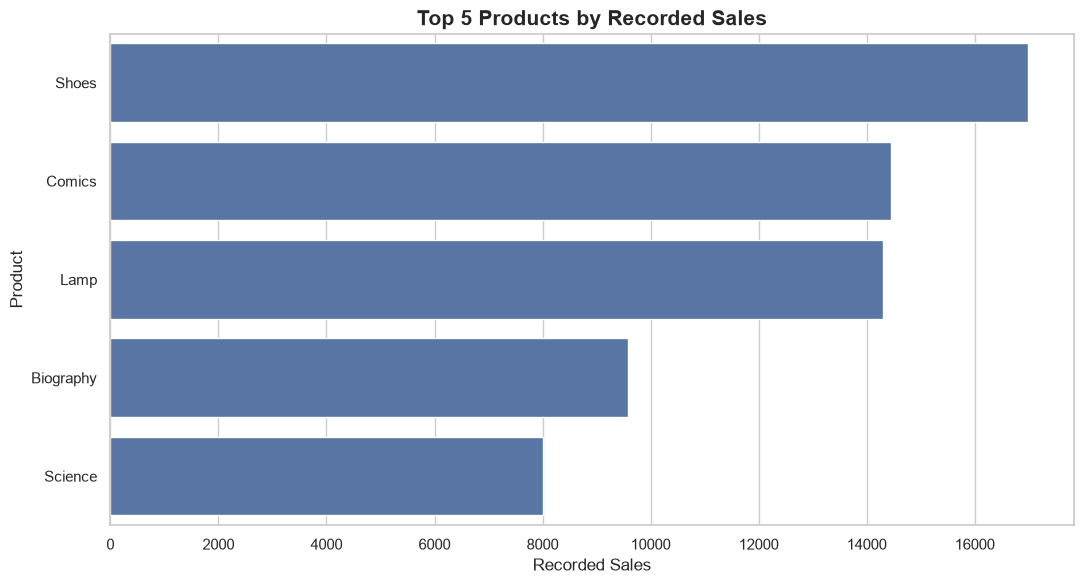

In [19]:

# ==========================================
# TOP 5 PRODUCTS SALES CHART
# ==========================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_5_sales,
    x="Recorded_Sales",
    y="Product"
)

plt.title(
    "Top 5 Products by Recorded Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recorded Sales")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


## Step 4: Identify the top five products by units sold

In [20]:

# ==========================================
# TOP 5 PRODUCTS BY QUANTITY SOLD
# ==========================================

top_5_quantity = product_analysis.sort_values(
    by="Total_Units_Sold",
    ascending=False
).head(5)

print("TOP 5 PRODUCTS BY UNITS SOLD")
print("=" * 45)

display(top_5_quantity)


TOP 5 PRODUCTS BY UNITS SOLD


,Product,Total_Units_Sold,Recorded_Sales,Transaction_Count,Valid_Sales_Records
13,Shoes,33.0,16987.080,9,8
3,Comics,25.0,14454.344,7,6
12,Science,24.0,8005.710,6,6
9,Lamp,23.0,14306.440,7,7
2,Blender,21.0,-11924.620,8,7


## Step 5: Visualize the top five products by quantity

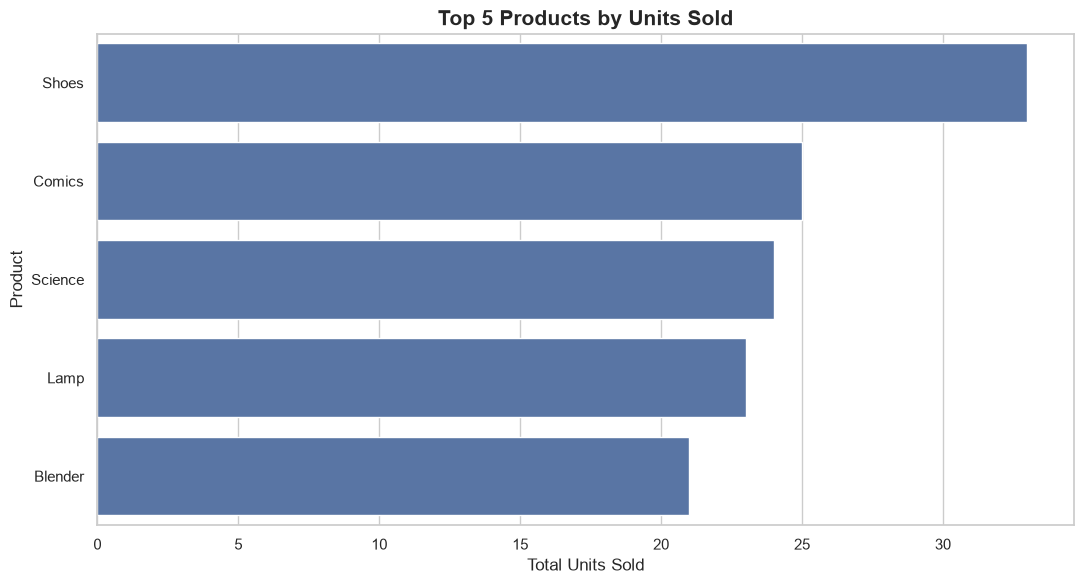

In [21]:

# ==========================================
# TOP 5 PRODUCTS QUANTITY CHART
# ==========================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_5_quantity,
    x="Total_Units_Sold",
    y="Product"
)

plt.title(
    "Top 5 Products by Units Sold",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Units Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


## Additional product investigation

In [22]:
# ==========================================
# PRODUCT-WISE NEGATIVE SALES INVESTIGATION
# ==========================================

negative_product_sales = (
    df[df["Total"] < 0]
    .groupby("Product")
    .agg(
        Negative_Transaction_Count=("Total", "count"),
        Negative_Recorded_Sales=("Total", "sum")
    )
    .reset_index()
)

print("PRODUCTS WITH NEGATIVE RECORDED SALES")
print("=" * 50)

display(negative_product_sales)

PRODUCTS WITH NEGATIVE RECORDED SALES


,Product,Negative_Transaction_Count,Negative_Recorded_Sales
0,Blender,1,-20000.00
1,T-Shirt,1,-2957.65
2,Vacuum,1,-300.00



### Key Findings – Product Performance Analysis

1. Shoes generated the highest recorded sales of 16,987.08 and recorded the highest quantity sold at 33 units.

2. Comics ranked second in recorded sales at 14,454.34, with 25 units sold.

3. Lamp generated 14,306.44 in recorded sales, with 23 units sold.

4. Science recorded 24 units sold, making it the third-highest product by quantity.

5. Blender recorded 21 units sold but showed negative recorded sales of -11,924.62, requiring investigation of negative transaction values.

### Business Recommendations

- Maintain sufficient inventory for high-demand products such as Shoes and Comics.
- Monitor product-wise sales and quantities together to understand purchasing patterns.
- Investigate negative transactions before making product-level business decisions.
- Review returned and cancelled orders to understand their impact on recorded sales.



## 4. Category-wise Sales Analysis

### Objective

Analyze sales and quantity performance across different product
categories to identify the strongest categories and understand
customer purchasing patterns.

### Key Metrics
- Category-wise Recorded Sales
- Category-wise Units Sold
- Category-wise Transaction Count
- Highest Performing Category
- Lowest Performing Category


## Step 1: Calculate category-wise performance

In [23]:

# ==========================================
# 4. CATEGORY-WISE SALES ANALYSIS
# ==========================================

category_analysis = (
    df.groupby("Category")
    .agg(
        Total_Units_Sold=("Quantity", "sum"),
        Recorded_Sales=("Total", "sum"),
        Transaction_Count=("Order_ID", "count"),
        Valid_Sales_Records=("Total", "count")
    )
    .reset_index()
    .sort_values(
        by="Recorded_Sales",
        ascending=False
    )
)

print("CATEGORY-WISE PERFORMANCE SUMMARY")
print("=" * 55)

display(category_analysis)


CATEGORY-WISE PERFORMANCE SUMMARY


,Category,Total_Units_Sold,Recorded_Sales,Transaction_Count,Valid_Sales_Records
0,Books,79.0,39320.910,23,22
1,Clothing,57.0,25761.190,17,14
3,Home,59.0,24429.710,20,17
4,Sports,44.0,17297.698,17,13
2,Electronics,47.0,518.102,23,21


## 2. Investigate missing categories and negative sales

In [24]:
# ==========================================
# CATEGORY DATA QUALITY INVESTIGATION
# ==========================================

# Records with missing categories
missing_category_records = df[
    df["Category"].isna()
]

print("RECORDS WITH MISSING CATEGORIES")
print("=" * 45)

display(
    missing_category_records[
        [
            "ID",
            "Product",
            "Category",
            "Quantity",
            "Price",
            "Total",
            "Status"
        ]
    ]
)

# Negative sales grouped by category
print("\nNEGATIVE SALES BY CATEGORY")
print("=" * 45)

display(
    df[df["Total"] < 0]
    .groupby("Category")
    .agg(
        Negative_Transactions=("Total", "count"),
        Negative_Sales=("Total", "sum")
    )
    .reset_index()
)

RECORDS WITH MISSING CATEGORIES


,ID,Product,Category,Quantity,Price,Total,Status
93,193,Basketball,NaN,NaN,522.02,NaN,Shipped
98,198,Vacuum,NaN,2.0,497.01,994.02,Shipped



NEGATIVE SALES BY CATEGORY


,Category,Negative_Transactions,Negative_Sales
0,Clothing,1,-2957.65
1,Electronics,1,-20000.00
2,Home,1,-300.00


## 3. Additional diagnostic: Category sales without negative totals

In [25]:
# ==========================================
# CATEGORY SALES SENSITIVITY ANALYSIS
# ==========================================

category_comparison = (
    df.dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Original_Recorded_Sales=("Total", "sum"),
        Sales_Excluding_Negative_Totals=(
            "Total",
            lambda x: x[x >= 0].sum()
        )
    )
    .reset_index()
)

print("CATEGORY SALES COMPARISON")
print("=" * 55)

display(
    category_comparison.sort_values(
        "Original_Recorded_Sales",
        ascending=False
    )
)

CATEGORY SALES COMPARISON


,Category,Original_Recorded_Sales,Sales_Excluding_Negative_Totals
0,Books,39320.910,39320.910
1,Clothing,25761.190,28718.840
3,Home,24429.710,24729.710
4,Sports,17297.698,17297.698
2,Electronics,518.102,20518.102


## Create category-wise sales chart

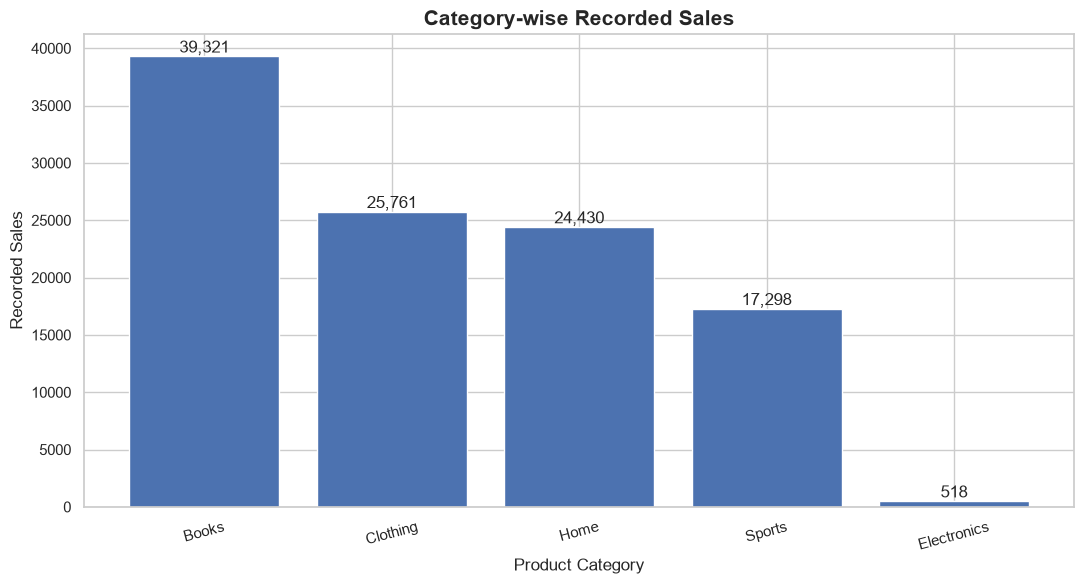

In [26]:

# ==========================================
# CATEGORY-WISE RECORDED SALES
# ==========================================

plt.figure(figsize=(11, 6))

category_sales = category_analysis.sort_values(
    "Recorded_Sales",
    ascending=False
)

bars = plt.bar(
    category_sales["Category"],
    category_sales["Recorded_Sales"]
)

plt.title(
    "Category-wise Recorded Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Recorded Sales")

plt.xticks(rotation=15)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()


## Create category-wise units sold chart

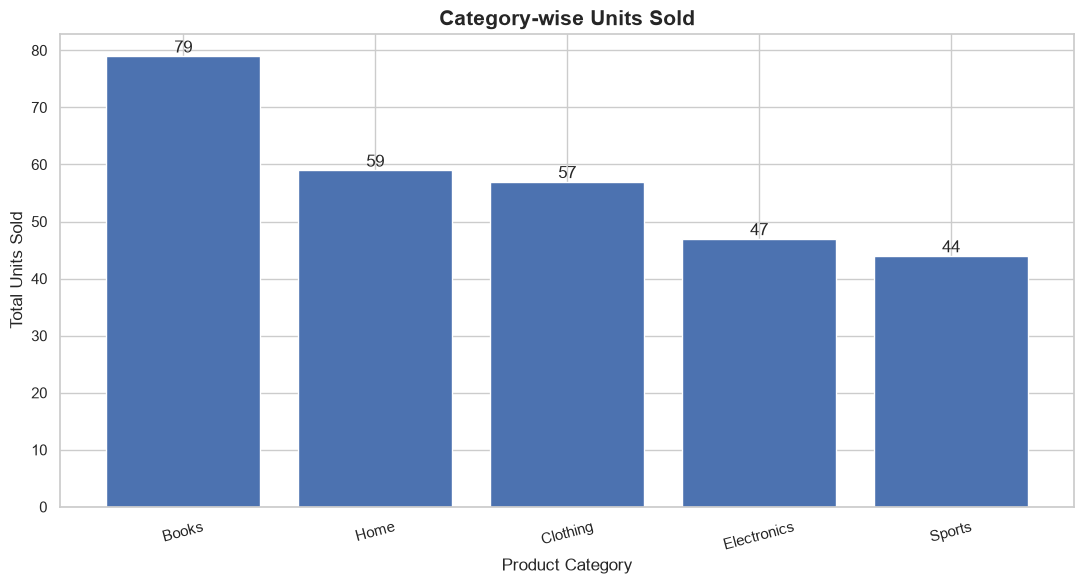

In [27]:

# ==========================================
# CATEGORY-WISE UNITS SOLD
# ==========================================

category_quantity = category_analysis.sort_values(
    "Total_Units_Sold",
    ascending=False
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    category_quantity["Category"],
    category_quantity["Total_Units_Sold"]
)

plt.title(
    "Category-wise Units Sold",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=15)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


## Create category contribution chart

,Category,Recorded_Sales,Sales_Contribution_Percentage
0,Books,39320.910,36.636342
1,Clothing,25761.190,24.002389
3,Home,24429.710,22.761813
4,Sports,17297.698,16.116727
2,Electronics,518.102,0.482729


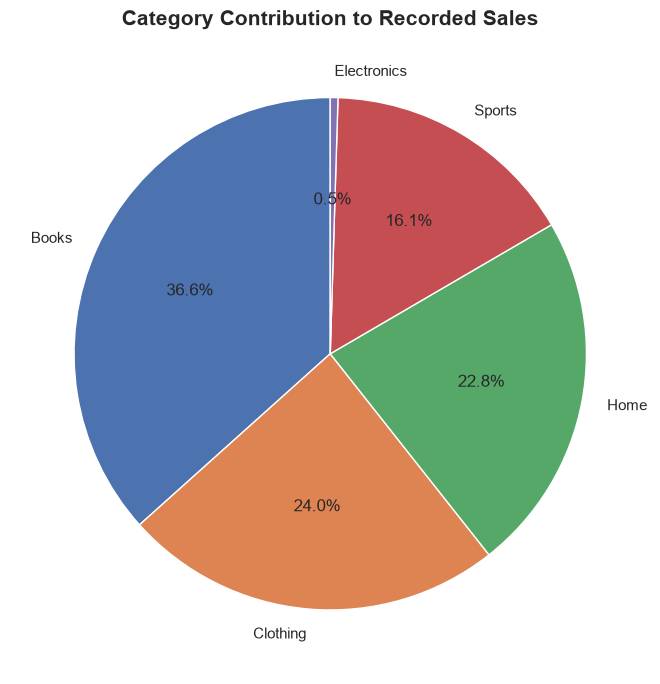

In [28]:

# ==========================================
# CATEGORY CONTRIBUTION TO RECORDED SALES
# ==========================================

category_contribution = category_analysis.copy()

total_category_sales = category_contribution[
    "Recorded_Sales"
].sum()

category_contribution["Sales_Contribution_Percentage"] = (
    category_contribution["Recorded_Sales"]
    / total_category_sales
) * 100

display(
    category_contribution[
        [
            "Category",
            "Recorded_Sales",
            "Sales_Contribution_Percentage"
        ]
    ].sort_values(
        "Recorded_Sales",
        ascending=False
    )
)

plt.figure(figsize=(9, 7))

plt.pie(
    category_contribution["Recorded_Sales"],
    labels=category_contribution["Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Category Contribution to Recorded Sales",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Key Findings – Category-wise Sales Analysis

1. Books is the highest-performing category, with recorded sales of 39,320.91 and 79 units sold.

2. Clothing ranks second in recorded sales, generating 25,761.19.

3. Home recorded 59 units sold, demonstrating strong product demand.

4. Electronics recorded only 518.10 in sales, significantly affected by a negative Blender transaction of -20,000.

5. Two transactions have missing category information and are excluded from category-level comparisons.

### Business Recommendations

- Maintain inventory availability for high-performing categories such as Books and Clothing.
- Investigate negative transactions before evaluating category profitability.
- Improve product-to-category mapping to prevent classification errors.
- Monitor category-wise sales and quantity together to identify demand patterns.



## 5. Customer Analysis

### Objective

Analyze customer purchasing behaviour, identify repeat customers,
and determine which customers contribute the most recorded sales.

### Key Metrics

- Total Unique Customers
- Customer-wise Recorded Sales
- Customer Transaction Frequency
- Customer-wise Units Purchased
- Top 10 Customers by Recorded Sales
- Repeat Customer Analysis


## Step 1: Customer-wise performance summary

In [29]:

# ==========================================
# 5. CUSTOMER ANALYSIS
# ==========================================

customer_analysis = (
    df.groupby("Customer_Name")
    .agg(
        Recorded_Sales=("Total", "sum"),
        Transaction_Count=("Order_ID", "count"),
        Unique_Orders=("Order_ID", "nunique"),
        Total_Units_Purchased=("Quantity", "sum"),
        Valid_Sales_Records=("Total", "count")
    )
    .reset_index()
)

customer_analysis = customer_analysis.sort_values(
    by="Recorded_Sales",
    ascending=False
)

print("CUSTOMER PERFORMANCE SUMMARY")
print("=" * 55)

print(
    "Total Unique Customers:",
    customer_analysis["Customer_Name"].nunique()
)

display(customer_analysis)


CUSTOMER PERFORMANCE SUMMARY
Total Unique Customers: 100


,Customer_Name,Recorded_Sales,Transaction_Count,Unique_Orders,Total_Units_Purchased,Valid_Sales_Records
42,Customer_142,5484.71,2,1,10.0,2
94,Customer_194,4722.70,1,1,5.0,1
49,Customer_149,4481.90,1,1,5.0,1
44,Customer_144,4245.35,1,1,5.0,1
43,Customer_143,4133.85,1,1,5.0,1
...,...,...,...,...,...,...
64,Customer_164,0.00,1,1,0.0,0
96,Customer_196,0.00,1,1,0.0,0
37,Customer_137,-300.00,1,1,3.0,1
34,Customer_134,-2957.65,1,1,0.0,1


## Step 2: Top 10 customers by recorded sales

In [30]:

# ==========================================
# TOP 10 CUSTOMERS BY RECORDED SALES
# ==========================================

top_10_customers = customer_analysis.head(10)

print("TOP 10 CUSTOMERS BY RECORDED SALES")
print("=" * 55)

display(top_10_customers)


TOP 10 CUSTOMERS BY RECORDED SALES


,Customer_Name,Recorded_Sales,Transaction_Count,Unique_Orders,Total_Units_Purchased,Valid_Sales_Records
42,Customer_142,5484.71,2,1,10.0,2
94,Customer_194,4722.70,1,1,5.0,1
49,Customer_149,4481.90,1,1,5.0,1
44,Customer_144,4245.35,1,1,5.0,1
43,Customer_143,4133.85,1,1,5.0,1
95,Customer_195,4087.30,1,1,5.0,1
54,Customer_154,3948.20,1,1,5.0,1
70,Customer_170,3708.15,1,1,5.0,1
26,Customer_126,3347.20,1,1,4.0,1
31,Customer_131,3083.15,1,1,5.0,1


## Step 3: Visualize top 10 customers

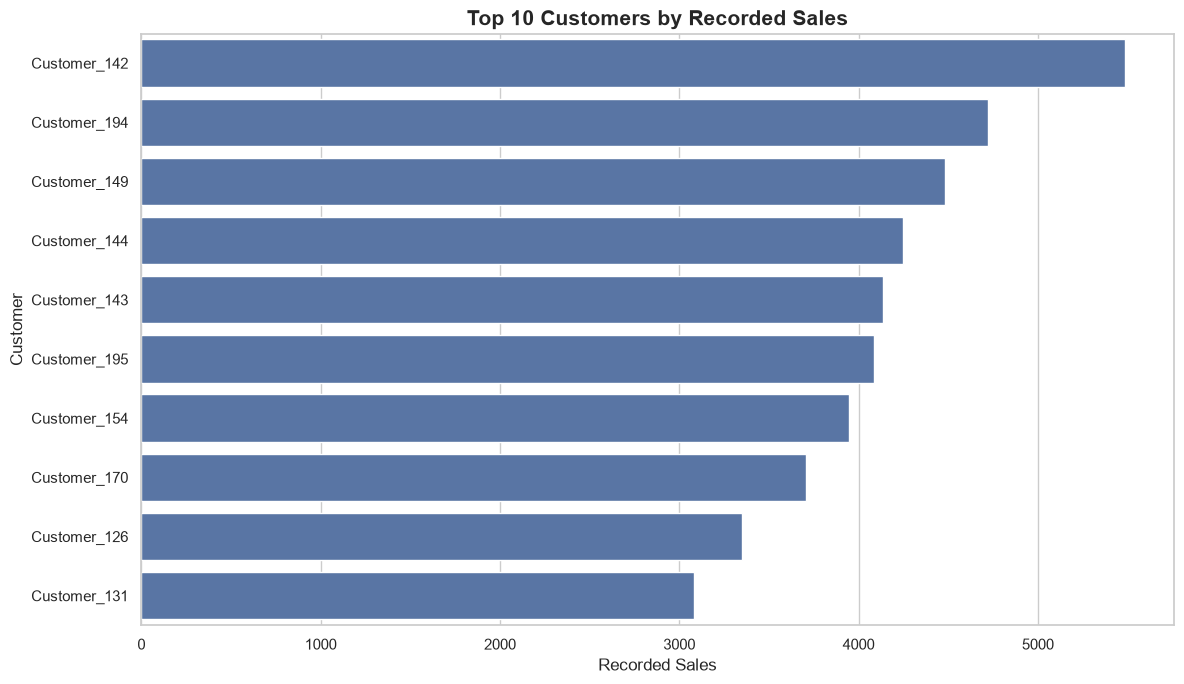

In [31]:

# ==========================================
# TOP 10 CUSTOMERS SALES CHART
# ==========================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_customers,
    x="Recorded_Sales",
    y="Customer_Name"
)

plt.title(
    "Top 10 Customers by Recorded Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recorded Sales")
plt.ylabel("Customer")

plt.tight_layout()
plt.show()


## Step 4: Identify repeat customers

In [32]:

# ==========================================
# REPEAT CUSTOMER ANALYSIS
# ==========================================

repeat_customers = customer_analysis[
    customer_analysis["Unique_Orders"] > 1
].sort_values(
    by="Unique_Orders",
    ascending=False
)

print("REPEAT CUSTOMER ANALYSIS")
print("=" * 50)

print(
    "Number of Repeat Customers:",
    len(repeat_customers)
)

display(repeat_customers)


REPEAT CUSTOMER ANALYSIS
Number of Repeat Customers: 0


,Customer_Name,Recorded_Sales,Transaction_Count,Unique_Orders,Total_Units_Purchased,Valid_Sales_Records


## Investigate Customer_142 and duplicate orders

In [33]:

# ==========================================
# CUSTOMER ORDER DUPLICATE INVESTIGATION
# ==========================================

# Identify customers associated with multiple rows
# but only one unique order ID

customer_order_check = (
    df.groupby("Customer_Name")
    .agg(
        Transaction_Rows=("Order_ID", "count"),
        Unique_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

customer_order_check["Possible_Duplicate_Rows"] = (
    customer_order_check["Transaction_Rows"]
    - customer_order_check["Unique_Orders"]
)

print("CUSTOMERS WITH POSSIBLE DUPLICATE ORDER RECORDS")
print("=" * 60)

display(
    customer_order_check[
        customer_order_check["Possible_Duplicate_Rows"] > 0
    ]
)

# Examine Customer_142's records
print("\nCUSTOMER_142 ORDER DETAILS")
print("=" * 45)

display(
    df[df["Customer_Name"] == "Customer_142"][
        [
            "ID",
            "Customer_Name",
            "Order_ID",
            "Order_Date",
            "Product",
            "Quantity",
            "Price",
            "Total",
            "Status"
        ]
    ]
)


CUSTOMERS WITH POSSIBLE DUPLICATE ORDER RECORDS


,Customer_Name,Transaction_Rows,Unique_Orders,Possible_Duplicate_Rows
42,Customer_142,2,1,1
75,Customer_175,2,1,1



CUSTOMER_142 ORDER DETAILS


,ID,Customer_Name,Order_ID,Order_Date,Product,Quantity,Price,Total,Status
42,142,Customer_142,ORD-69018,2025-10-30,Shoes,5.0,645.26,2258.41,Shipped
101,142,Customer_142,ORD-69018,2025-10-30,Shoes,5.0,645.26,3226.30,Shipped



### Key Findings – Customer Analysis

1. The dataset contains 100 unique customers.

2. Customer_142 recorded the highest sales value of 5,484.71, followed by Customer_194 with 4,722.70.

3. Customer_149 ranked third, with recorded sales of 4,481.90.

4. No customers have multiple unique order IDs in the current dataset.

5. Customer_142 has two records associated with the same Order ID, requiring duplicate-order investigation.

### Business Recommendations

- Identify high-value customers and understand their purchasing preferences.
- Maintain customer engagement through personalized offers and loyalty programs.
- Investigate duplicate order records to improve customer-level reporting accuracy.
- Monitor repeat purchasing behaviour as more transaction data becomes available.


## Investigate Customer_175

In [34]:

# ==========================================
# CUSTOMER_175 ORDER DETAILS
# ==========================================

print("CUSTOMER_175 ORDER DETAILS")
print("=" * 45)

display(
    df[df["Customer_Name"] == "Customer_175"][
        [
            "ID",
            "Customer_Name",
            "Order_ID",
            "Order_Date",
            "Product",
            "Quantity",
            "Price",
            "Total",
            "Status"
        ]
    ]
)


CUSTOMER_175 ORDER DETAILS


,ID,Customer_Name,Order_ID,Order_Date,Product,Quantity,Price,Total,Status
75,175,Customer_175,ORD-56651,2025-02-24,Headphones,1.0,111.36,111.360,Processing
100,175,Customer_175,ORD-56651,2025-02-24,Headphones,1.0,111.36,77.952,Processing



### Customer Data Quality Findings

1. The dataset contains 100 unique customers.

2. No customer has more than one unique Order ID, so no repeat customers are identified in the current dataset.

3. Customer_142 and Customer_175 each have two records associated with the same Order ID.

4. Both duplicate-order cases contain different recorded totals despite having matching order details.

5. These records require business verification before customer sales figures can be treated as final.

### Recommendation

Introduce order-level validation using Order_ID and investigate conflicting totals before calculating final customer revenue or repeat-purchase metrics.


## duplicate-order investigation section

In [36]:
# ==========================================
# RELOAD CLEANED DATASET
# ==========================================

import pandas as pd

cleaned_df = pd.read_csv(
    "../dataset/cleaned_ecommerce_sales.csv"
)

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", cleaned_df.shape)

Cleaned dataset loaded successfully!
Dataset shape: (102, 15)


In [37]:
# ==========================================
# DUPLICATE ORDER INVESTIGATION
# ==========================================

duplicate_orders = cleaned_df[
    cleaned_df["Order_ID"].duplicated(keep=False)
].sort_values(["Customer_Name", "Order_ID"])

print("POSSIBLE DUPLICATE ORDER RECORDS")
print("=" * 50)

display(duplicate_orders)

POSSIBLE DUPLICATE ORDER RECORDS


,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total,Original_Total,Gross_Amount,Total_Difference,Total_Check
42,142,Customer_142,ORD-69018,2025-10-30,Shoes,Clothing,5.0,645.26,Credit Card,Shipped,2258.410,2258.410,3226.30,967.890,Difference - Investigate
101,142,Customer_142,ORD-69018,2025-10-30,Shoes,Clothing,5.0,645.26,Credit Card,Shipped,3226.300,3226.300,3226.30,0.000,Matches Gross Amount
75,175,Customer_175,ORD-56651,2025-02-24,Headphones,Electronics,1.0,111.36,Credit Card,Processing,111.360,111.360,111.36,0.000,Matches Gross Amount
100,175,Customer_175,ORD-56651,2025-02-24,Headphones,Electronics,1.0,111.36,Credit Card,Processing,77.952,77.952,111.36,33.408,Difference - Investigate


## Order Status Analysis

In [38]:
# ==========================================
# ORDER STATUS PERFORMANCE ANALYSIS
# ==========================================

status_summary = (
    cleaned_df.groupby("Status")
    .agg(
        Transaction_Count=("Order_ID", "count"),
        Unique_Orders=("Order_ID", "nunique"),
        Recorded_Sales=("Total", "sum"),
        Valid_Sales_Records=("Total", "count"),
        Total_Units_Sold=("Quantity", "sum")
    )
    .sort_values("Recorded_Sales", ascending=False)
)

print("ORDER STATUS PERFORMANCE SUMMARY")
print("=" * 60)

display(status_summary.round(2))

ORDER STATUS PERFORMANCE SUMMARY


,Transaction_Count,Unique_Orders,Recorded_Sales,Valid_Sales_Records,Total_Units_Sold
Status,,,,,
Returned,27,27,37999.12,24,72.0
Shipped,23,22,29562.19,21,77.0
Cancelled,15,15,23005.49,12,52.0
Delivered,11,11,12706.70,10,23.0
Processing,26,25,5048.14,21,64.0


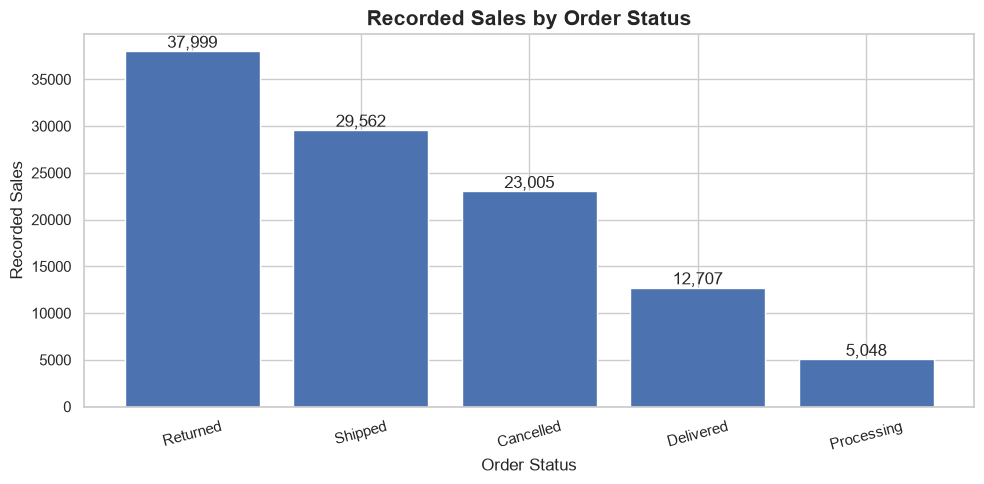

In [39]:
# ==========================================
# SALES BY ORDER STATUS
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    status_summary.index,
    status_summary["Recorded_Sales"]
)

plt.title(
    "Recorded Sales by Order Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Order Status")
plt.ylabel("Recorded Sales")
plt.xticks(rotation=15)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()

## Payment Method Analysis

### Payment method performance summary

In [40]:
# ==========================================
# PAYMENT METHOD PERFORMANCE ANALYSIS
# ==========================================

payment_summary = (
    cleaned_df.groupby("Payment_Method")
    .agg(
        Transaction_Count=("Order_ID", "count"),
        Unique_Orders=("Order_ID", "nunique"),
        Recorded_Sales=("Total", "sum"),
        Valid_Sales_Records=("Total", "count"),
        Total_Units_Sold=("Quantity", "sum")
    )
    .sort_values("Recorded_Sales", ascending=False)
)

print("PAYMENT METHOD PERFORMANCE SUMMARY")
print("=" * 60)

display(payment_summary.round(2))

PAYMENT METHOD PERFORMANCE SUMMARY


,Transaction_Count,Unique_Orders,Recorded_Sales,Valid_Sales_Records,Total_Units_Sold
Payment_Method,,,,,
Bank Transfer,22,22,41612.83,19,68.0
Credit Card,23,21,24076.33,20,63.0
PayPal,24,24,21390.82,20,61.0
Cash on Delivery,33,33,21241.64,29,96.0


### Transactions by payment method

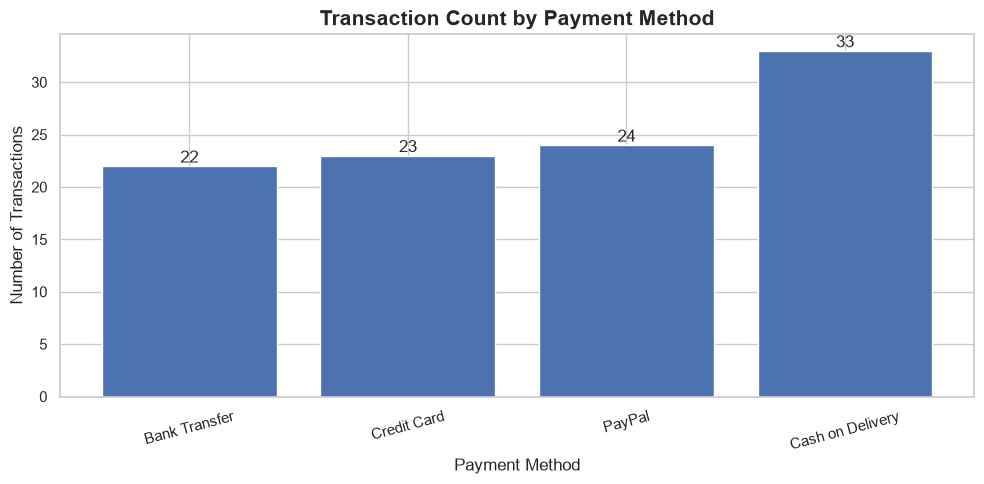

In [41]:
# ==========================================
# TRANSACTION COUNT BY PAYMENT METHOD
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    payment_summary.index,
    payment_summary["Transaction_Count"]
)

plt.title(
    "Transaction Count by Payment Method",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=15)

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Recorded sales by payment method

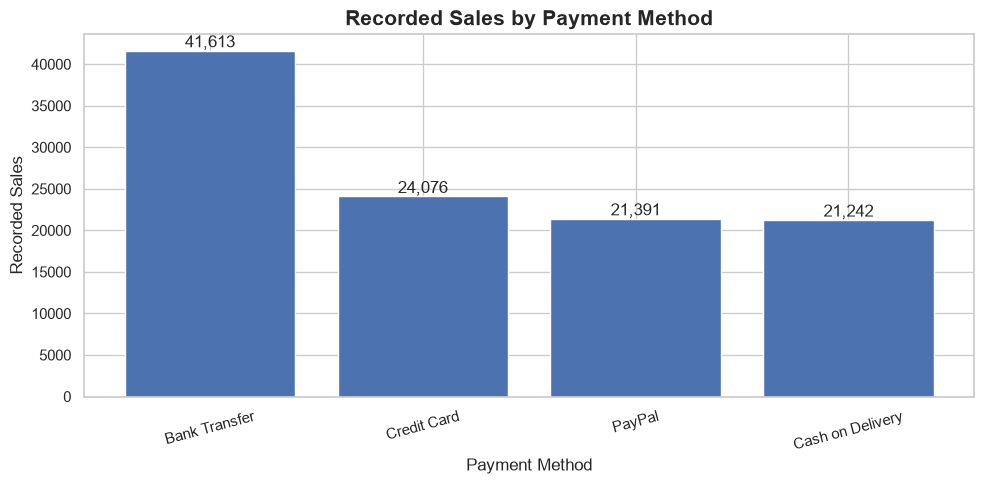

In [42]:
# ==========================================
# RECORDED SALES BY PAYMENT METHOD
# ==========================================

plt.figure(figsize=(10, 5))

bars = plt.bar(
    payment_summary.index,
    payment_summary["Recorded_Sales"]
)

plt.title(
    "Recorded Sales by Payment Method",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Payment Method")
plt.ylabel("Recorded Sales")
plt.xticks(rotation=15)

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()

## DATA QUALITY AND VALIDATION ANALYSIS

In [43]:
# ==========================================
# DATA QUALITY SUMMARY
# ==========================================

quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Missing Order Dates",
        "Missing Categories",
        "Missing Quantities",
        "Missing Prices",
        "Missing Sales Values",
        "Duplicate IDs",
        "Duplicate Order IDs",
        "Negative Sales Records"
    ],
    "Count": [
        len(cleaned_df),
        cleaned_df["Order_Date"].isna().sum(),
        cleaned_df["Category"].isna().sum(),
        cleaned_df["Quantity"].isna().sum(),
        cleaned_df["Price"].isna().sum(),
        cleaned_df["Total"].isna().sum(),
        cleaned_df["ID"].duplicated().sum(),
        cleaned_df["Order_ID"].duplicated().sum(),
        (cleaned_df["Total"] < 0).sum()
    ]
})

display(quality_summary)

,Metric,Count
0,Total Records,102
1,Missing Order Dates,1
2,Missing Categories,2
3,Missing Quantities,8
4,Missing Prices,8
5,Missing Sales Values,14
6,Duplicate IDs,2
7,Duplicate Order IDs,2
8,Negative Sales Records,3


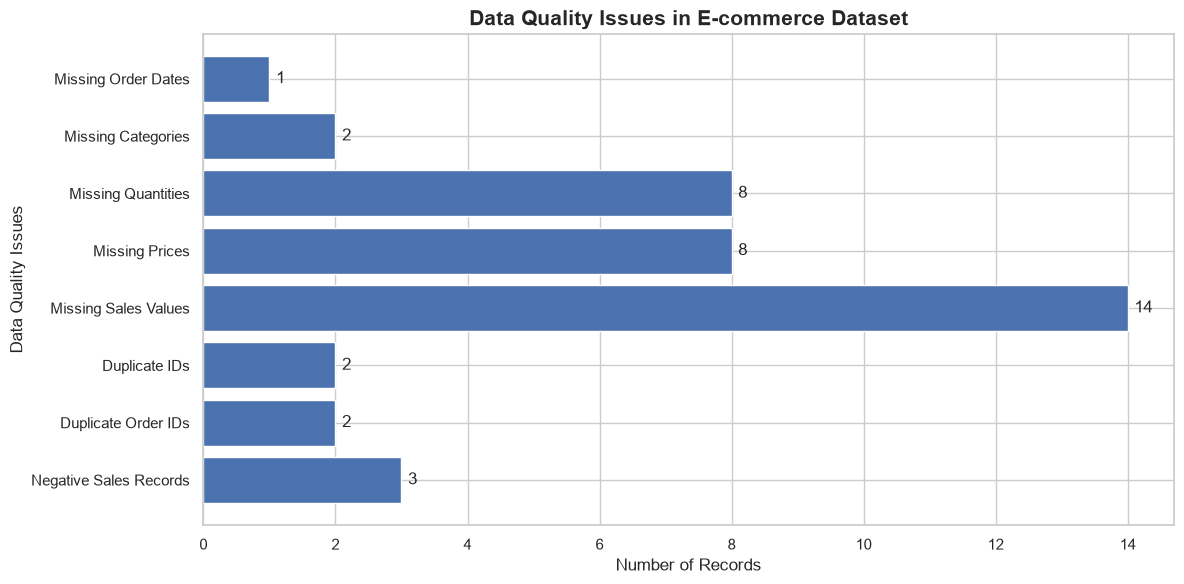

In [44]:
# ==========================================
# DATA QUALITY ISSUES VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

quality_plot = quality_summary[
    quality_summary["Metric"] != "Total Records"
]

plt.figure(figsize=(12, 6))

bars = plt.barh(
    quality_plot["Metric"],
    quality_plot["Count"]
)

plt.title(
    "Data Quality Issues in E-commerce Dataset",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Records")
plt.ylabel("Data Quality Issues")
plt.gca().invert_yaxis()

for bar in bars:
    plt.text(
        bar.get_width() + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

# Business Insights and Recommendations

## 1. Monthly Sales Performance
**Insight:** June 2025 recorded the highest sales, with 16,376.43. February 2025 recorded negative sales of -830.71, indicating unusual transactions that require investigation.

**Recommendation:** Investigate negative transactions and monitor monthly sales trends to identify seasonal patterns and opportunities for growth.

## 2. Best-Performing Products
**Insight:** Shoes generated the highest recorded product sales of 16,987.08, with 33 units sold. Comics and Lamp followed with 14,454.34 and 14,306.44, respectively.

**Recommendation:** Maintain sufficient inventory for popular products and consider targeted promotions to increase sales of lower-performing products.

## 3. Category-Wise Sales Performance
**Insight:** Books was the highest-performing category, generating recorded sales of 39,320.91. Electronics recorded only 518.10, largely because of a negative sales transaction of -20,000.

**Recommendation:** Continue supporting strong-performing categories while investigating unusual transactions before making decisions based on category sales.

## 4. Customer Performance
**Insight:** Customer_142 had the highest recorded sales value of 5,484.71. However, the customer has two records associated with the same Order ID, with different recorded totals. The dataset shows no repeat customers when repeat purchases are measured using distinct Order IDs.

**Recommendation:** Investigate repeated order records and introduce customer retention strategies, such as loyalty programs and personalized offers.

## 5. Order Status Performance
**Insight:** Returned orders had the highest recorded sales value of 37,999.12, followed by Shipped orders at 29,562.19. Cancelled orders represented 15 transactions with recorded sales of 23,005.49.

**Recommendation:** Analyze the reasons behind returns and cancellations, improve product descriptions and quality checks, and monitor order fulfillment.

## 6. Payment Method Performance
**Insight:** Bank Transfer generated the highest recorded sales of 41,612.83. Cash on Delivery had the highest transaction count (33) and units sold (96).

**Recommendation:** Continue supporting popular payment methods while evaluating payment-related customer preferences and encouraging convenient digital payment options.

## 7. Negative Sales Transactions
**Insight:** Three records contained negative sales values, affecting the February 2025 monthly sales figure and the performance of Blender, T-Shirt, and Vacuum.

**Recommendation:** Verify these transactions against the original order records. Establish validation rules to prevent invalid quantities, prices, and sales values from affecting future reports.

## 8. Data Quality Issues
**Insight:** The dataset contained missing order dates (1), categories (2), quantities (8), prices (8), sales values (14), repeated IDs (2), repeated Order IDs (2), and negative sales records (3).

**Recommendation:** Implement data validation, mandatory field checks, duplicate-order investigation, and regular data-quality monitoring before generating business reports.

## Overall Conclusion
The analysis identifies Books as the strongest sales category, Shoes as the leading product, and Bank Transfer as the highest-value payment method based on recorded sales. However, missing values, negative transactions, and repeated order identifiers affect the reliability of some results. Resolving these issues will help the business make more accurate and informed decisions.